In [1]:
%matplotlib inline
import json
import time

import matplotlib.pyplot as plt
import numpy as np

from stem_agent.config import INSTRUMENTS



from langgraph.graph import END, START, StateGraph
from stem_agent.states.experiment_state import ParticleRunState

# from stem_agent.config import LIMITS, TUNING
# from stem_agent.mcp import session                                  # MCP calls: session.call("get_fov"), ...
# from stem_agent.data import tiled_io                                 # full images from Tiled
# from stem_agent.nodes.common import acquire_haadf, get_stage, move_stage
# from stem_agent.analysis.metrics import all_metrics, contrast, edge_sharpness
# from stem_agent.analysis.optimizer import QuadraticSearch
# from stem_agent.utils.plots import plot_search

from stem_agent.nodes.preflight_node import preflight_node
from stem_agent.nodes.status_node import status_node
from stem_agent.nodes.tune_node import next_step, tune_node
from stem_agent.nodes.save_node import save_node

In [29]:
settings = {
    "instrument": "real",          # "twin" or "real"
    "run_tag": "autotune",
    # "protocol": [                  # fov_m None = keep the current FOV (calibrate, then fill in)
    #     #{"name": "z_10k",  "tune": "z",  "fov_m": 0.75e-6, "step_m": 50e-6,  "max_offset_m": 200e-6, "min_step_m": 500e-9},
    #     #{"name": "z_100k", "tune": "z",  "fov_m": .2e-6, "step_m": 1000e-9, "max_offset_m": 1e-6, "min_step_m": 100e-9},
    #     #{"name": "C1_1M",  "tune": "C1", "fov_m": 100e-9, "step_m": 50e-9,   "max_offset_m": 800e-9, "min_step_m": 15e-9},
    #     #{"name": "C1_5M",  "tune": "C1", "fov_m": 16e-9, "step_m": 2e-9,   "max_offset_m": 10e-9, "min_step_m": 15e-9},
    # {"name": "z",  "tune": "z",  "fov_m": 0.2e-6, "step_m": 1e-6,  "max_offset_m": 1e-6,   "min_step_m": 100e-9},
    # {"name": "C1", "tune": "C1", "fov_m": 100e-9, "method": "grid", "step_m": 50e-9, "max_offset_m": 400e-9, "min_step_m": 15e-9}
    # ],
    "protocol": [
    {"name": "z_coarse",  "tune": "z",  "fov_m": .75e-6, "method": "grid", "step_m": 3e-6, "max_offset_m": 20e-6,   "min_step_m": 100e-9},
    {"name": "z", "tune": "z", "fov_m": 0.75e-6, "method": "grid", "step_m": 200e-9, "max_offset_m": 4e-6, "min_step_m": 100e-9},
    #{"name": "C1", "tune": "C1", "fov_m": 100e-9, "method": "grid", "step_m": 50e-9,  "max_offset_m": 400e-9, "min_step_m": 15e-9},
],
}

state = {"settings": settings}
state |= await preflight_node(state)
state |= await status_node(state)

[preflight] real at http://10.46.217.241:8000/mcp: 14/14 tools, Tiled http://10.46.217.241:9091, run folder /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261107_132807_autotune
opened
[status 00 gate] stage [+0.000141, +0.000149, +6.87e-05, +0.00519, +0] | FOV 7.500000265281415e-07 m | devices 9 (all ON) | ready True


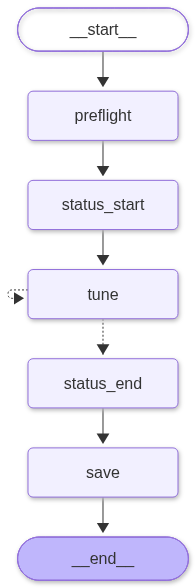

In [8]:
def go(next_node):
    return lambda state: "status_end" if state.get("run_status") == "failed" else next_node


def after_tune(state):
    if state.get("run_status") == "failed":
        return "status_end"
    return "tune" if next_step(state) else "status_end"


builder = StateGraph(ParticleRunState)
builder.add_node("preflight", preflight_node)
builder.add_node("status_start", status_node)
builder.add_node("tune", tune_node)
builder.add_node("status_end", status_node)
builder.add_node("save", save_node)

builder.add_edge(START, "preflight")
builder.add_edge("preflight", "status_start")
builder.add_edge("status_start", "tune")
builder.add_conditional_edges("tune", after_tune, ["tune", "status_end"])
builder.add_edge("status_end", "save")
builder.add_edge("save", END)

graph = builder.compile()
graph

In [30]:
state = await graph.ainvoke(state)

[preflight] real at http://10.46.217.241:8000/mcp: 14/14 tools, Tiled http://10.46.217.241:9091, run folder /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261107_132812_autotune
opened
[status 00 gate] stage [+0.000141, +0.000149, +6.87e-05, +0.00519, +0] | FOV 7.500000265281415e-07 m | devices 9 (all ON) | ready True
[tune z_coarse]  1 grid  offset [-17.999] um  contrast 0.36819
[tune z_coarse]  2 grid  offset [-15.001] um  contrast 0.34632
[tune z_coarse]  3 grid  offset [-12.002] um  contrast 0.40393
[tune z_coarse]  4 grid  offset [-9.003] um  contrast 0.4756
[tune z_coarse]  5 grid  offset [-5.997] um  contrast 0.51444
[tune z_coarse]  6 grid  offset [-2.999] um  contrast 0.57885
[tune z_coarse]  7 grid  offset [0.0] um  contrast 0.68707
[tune z_coarse]  8 grid  offset [2.992] um  contrast 0.81811
[tune z_coarse]  9 grid  offset [5.997] um  contrast 0.73822
[tune z_coarse] 10 grid  offset [9.003] um  contrast 0.6356
[tune z_coarse] 11 grid  offset [12.002] um  

In [23]:
import json

import numpy as np

from stem_agent.data import tiled_io
from stem_agent.mcp import session
from stem_agent.nodes import common


async def sam_particles(detector: str = "haadf") -> dict:
    """HAADF -> SAM2 segmentation device. Particles, mask and centroids exactly as SAM returns them."""
    image_key, image = await common.acquire_haadf(detector)
    labels_key = await session.call_tool("SEGMENTATION_segment", image_key)
    node = tiled_io._tiled()[labels_key]
    labels = np.asarray(node.read())                          # 0 = background, 1..N = SAM regions
    particles = []
    for area in node.metadata.get("area_statistics", []):     # SAM's stats, largest first
        x, y = json.loads(await session.call_tool("SEGMENTATION_get_centroid", area["id"]))
        particles.append({**area, "row": y, "col": x})        # SAM centroid; [x, y] = [col, row]
    return {"image_key": image_key, "image": image, "labels_key": labels_key,
            "labels": labels, "mask": labels > 0, "particles": particles}

[preflight] real at http://10.46.217.241:8000/mcp: 14/14 tools, Tiled http://10.46.217.241:9091, run folder /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261107_115729_sam
104 particles


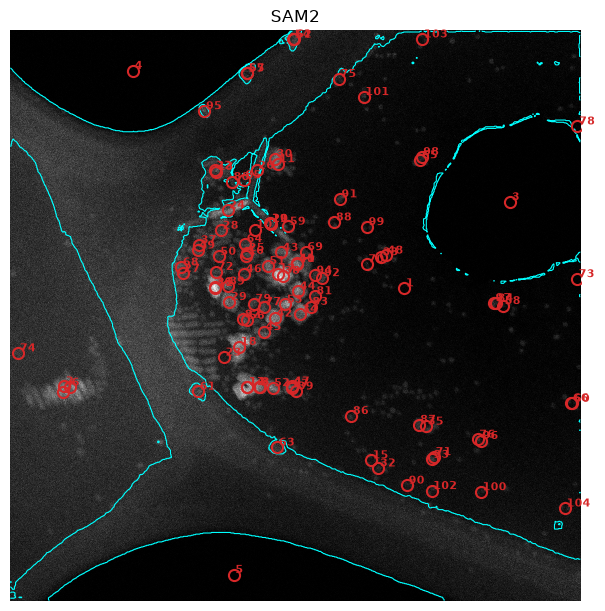

In [24]:
from stem_agent.nodes.preflight_node import preflight_node
from stem_agent.utils.plots import plot_particles

state = {"settings": {"instrument": "real", "run_tag": "sam"}}
state |= await preflight_node(state)

result = await sam_particles()
print(len(result["particles"]), "particles")
plot_particles(result["image"], result["labels"], result["particles"], "SAM2")

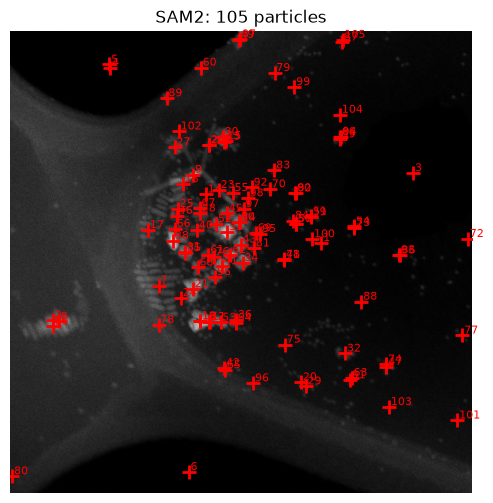

In [25]:
import matplotlib.pyplot as plt

result = await sam_particles()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(result["image"], cmap="gray")
for p in result["particles"]:
    ax.plot(p["col"], p["row"], "r+", ms=10, mew=2)
    ax.text(p["col"] + 4, p["row"] - 4, str(p["id"]), color="red", fontsize=8)
ax.set_title(f"SAM2: {len(result['particles'])} particles")
ax.axis("off")
plt.show()

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi

from stem_agent.data import tiled_io
from stem_agent.mcp import session
from stem_agent.nodes import common


def clean_sam_labels(labels: np.ndarray, areas: list[dict], min_visible: float = 0.5) -> np.ndarray:
    """One region per particle from SAM's overlapping masks."""
    labels = labels.copy()
    for a in areas:                                   # 1) mostly hidden by smaller masks: drop
        own = labels == a["id"]
        if own.sum() < min_visible * a["area_px"]:
            labels[own] = 0
    for k in np.unique(labels)[::-1]:                 # 2) inside one other region: merge (small first)
        if k == 0:
            continue
        ring = ndi.binary_dilation(labels == k) & (labels != k)
        around = np.unique(labels[ring])
        if len(around) == 1 and around[0] != 0:
            labels[labels == k] = around[0]
    return labels


async def sam_scan(detector: str = "haadf", min_visible: float = 0.5) -> dict:
    """Scan -> SAM2 segmentation device -> one region and one centre per particle, plotted."""
    image_key, image = await common.acquire_haadf(detector)                    # scan
    labels_key = await session.call_tool("SEGMENTATION_segment", image_key)    # SAM2
    node = tiled_io._tiled()[labels_key]
    raw = np.asarray(node.read())                                              # 0 = background, 1..N
    labels = clean_sam_labels(raw, node.metadata.get("area_statistics", []), min_visible)
    ids = [int(k) for k in np.unique(labels) if k]
    centres = ndi.center_of_mass(labels > 0, labels, ids)
    particles = [{"id": k, "row": float(r), "col": float(c)} for k, (r, c) in zip(ids, centres)]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image, cmap="gray")
    ax.contour(labels, levels=np.arange(labels.max()) + 0.5, colors="cyan", linewidths=0.8)
    for p in particles:
        ax.plot(p["col"], p["row"], "r+", ms=10, mew=2)
        ax.text(p["col"] + 4, p["row"] - 4, str(p["id"]), color="red", fontsize=8)
    ax.set_title(f"SAM2: {len(particles)} particles")
    ax.axis("off")
    plt.show()
    return {"image_key": image_key, "labels_key": labels_key, "image": image,
            "raw_labels": raw, "labels": labels, "particles": particles}

[preflight] real at http://10.46.217.241:8000/mcp: 14/14 tools, Tiled http://10.46.217.241:9091, run folder /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261107_122920_sam


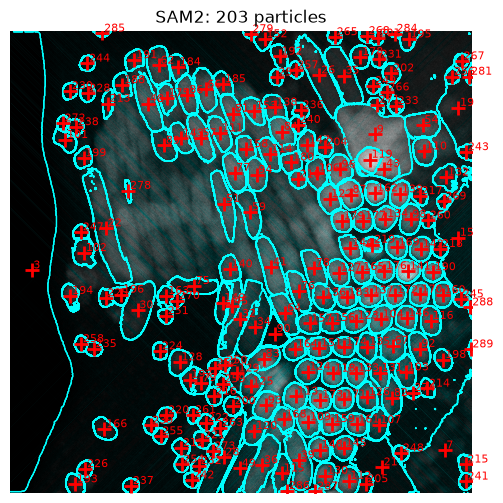

In [34]:
state = {"settings": {"instrument": "real", "run_tag": "sam"}}
state |= await preflight_node(state)
result = await sam_scan()